Mounted at /content/drive
Image CRS: EPSG:32618
GeoJSON CRS: EPSG:4326


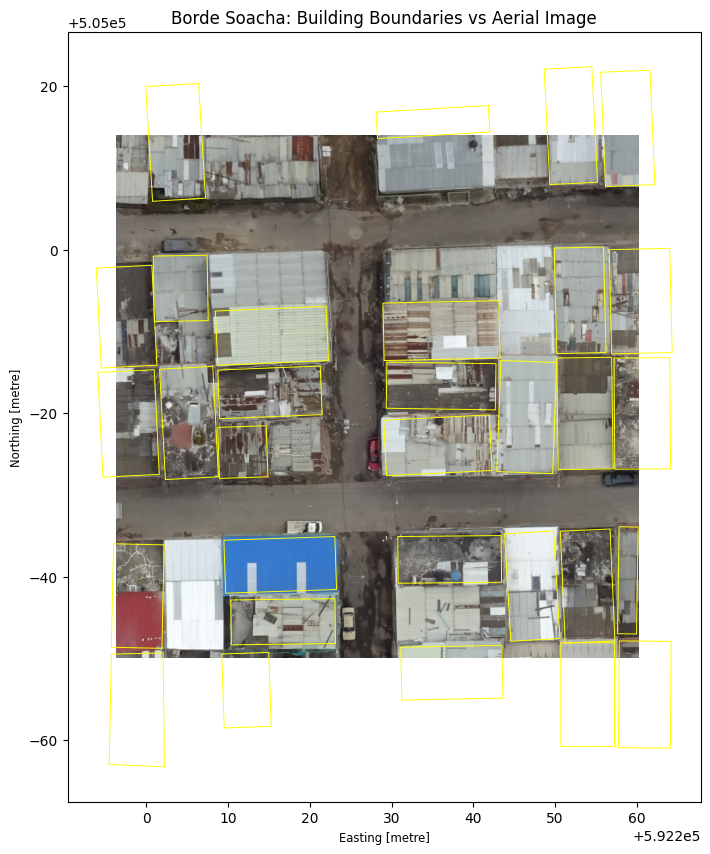

Buildings visible in this window: 31


In [ ]:

from google.colab import drive
drive.mount('/content/drive')

import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt
from rasterio.plot import show

base = "/content/drive/MyDrive/RoofMaterialProject/borde_soacha"

image_path = f"{base}/borde_soacha_ortho-cog.tif"
geojson_path = f"{base}/train-borde_soacha.geojson"

# Load building boundaries
buildings = gpd.read_file(geojson_path)

# Open aerial image
with rasterio.open(image_path) as src:
    print("Image CRS:", src.crs)
    print("GeoJSON CRS:", buildings.crs)

    # Convert boundaries to the image coordinate system
    buildings = buildings.to_crs(src.crs)

    # Plot a small image window near the centre
    width = min(1500, src.width)
    height = min(1500, src.height)

    col = src.width // 2
    row = src.height // 2

    window = rasterio.windows.Window(
        max(0, col - width // 2),
        max(0, row - height // 2),
        min(width, src.width - max(0, col - width // 2)),
        min(height, src.height - max(0, row - height // 2))
    )

    image = src.read([1, 2, 3], window=window)
    transform = src.window_transform(window)

fig, ax = plt.subplots(figsize=(12, 10))

show(image, transform=transform, ax=ax)

# Draw only buildings intersecting this image window
from shapely.geometry import box

left, bottom, right, top = rasterio.windows.bounds(window, src.transform)
view_area = box(left, bottom, right, top)
visible = buildings[buildings.intersects(view_area)]

visible.boundary.plot(ax=ax, color="yellow", linewidth=0.7)

ax.set_title("Borde Soacha: Building Boundaries vs Aerial Image")
plt.show()

print("Buildings visible in this window:", len(visible))


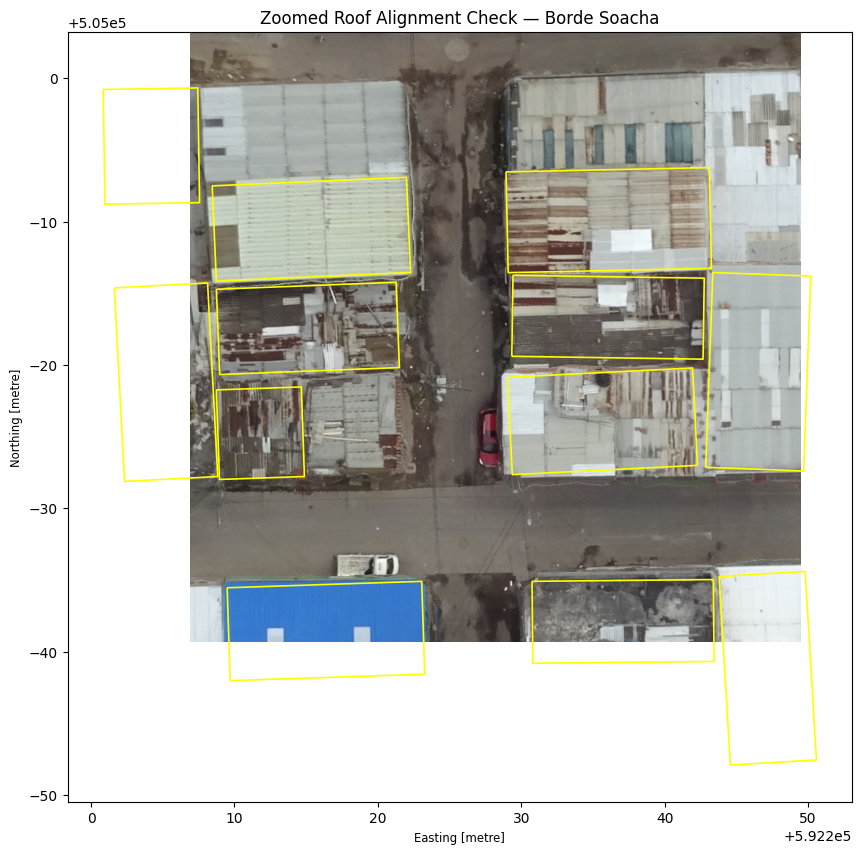

Buildings visible in this window: 12


In [ ]:

import matplotlib.pyplot as plt
import rasterio
import geopandas as gpd
from rasterio.plot import show
from shapely.geometry import box

base = "/content/drive/MyDrive/RoofMaterialProject/borde_soacha"
image_path = f"{base}/borde_soacha_ortho-cog.tif"
geojson_path = f"{base}/train-borde_soacha.geojson"

buildings = gpd.read_file(geojson_path)

with rasterio.open(image_path) as src:
    buildings = buildings.to_crs(src.crs)

    # Zoom into the central part of the image
    col, row = src.width // 2, src.height // 2
    window = rasterio.windows.Window(
        col - 500, row - 500, 1000, 1000
    )

    image = src.read([1, 2, 3], window=window)
    transform = src.window_transform(window)
    left, bottom, right, top = rasterio.windows.bounds(
        window, src.transform
    )

view = box(left, bottom, right, top)
visible = buildings[buildings.intersects(view)]

fig, ax = plt.subplots(figsize=(12, 10))
show(image, transform=transform, ax=ax)
visible.boundary.plot(ax=ax, color="yellow", linewidth=1.2)

ax.set_title("Zoomed Roof Alignment Check — Borde Soacha")
plt.show()
print("Buildings visible in this window:", len(visible))


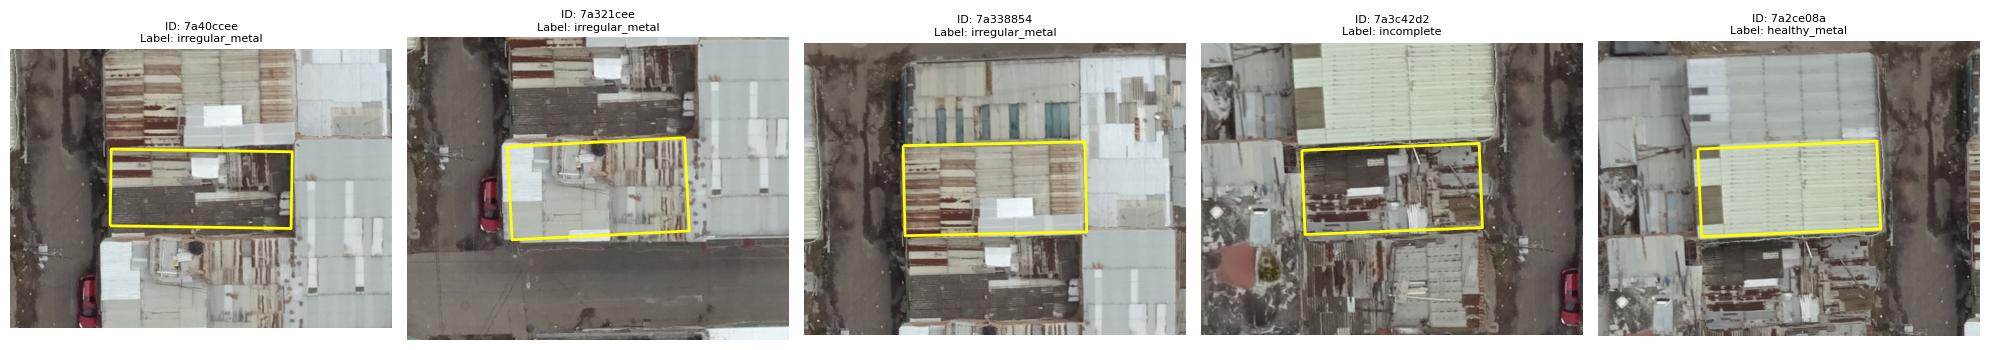

In [ ]:

import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt
from rasterio.plot import show
from rasterio.windows import from_bounds
from shapely.geometry import box

base = "/content/drive/MyDrive/RoofMaterialProject/borde_soacha"
image_path = f"{base}/borde_soacha_ortho-cog.tif"
geojson_path = f"{base}/train-borde_soacha.geojson"

gdf = gpd.read_file(geojson_path)

with rasterio.open(image_path) as src:
    gdf = gdf.to_crs(src.crs)

    # Select 5 buildings from the central image area
    centre_x = (src.bounds.left + src.bounds.right) / 2
    centre_y = (src.bounds.bottom + src.bounds.top) / 2

    candidates = gdf.copy()
    candidates["distance"] = (
        candidates.geometry.centroid.x.sub(centre_x) ** 2
        + candidates.geometry.centroid.y.sub(centre_y) ** 2
    )
    sample = candidates.nsmallest(5, "distance")

    fig, axes = plt.subplots(1, 5, figsize=(20, 5))

    for ax, (_, building) in zip(axes, sample.iterrows()):
        # Crop around each building with some surrounding context
        minx, miny, maxx, maxy = building.geometry.bounds
        pad = max(maxx - minx, maxy - miny) * 0.4 + 2

        minx, maxx = max(minx - pad, src.bounds.left), min(maxx + pad, src.bounds.right)
        miny, maxy = max(miny - pad, src.bounds.bottom), min(maxy + pad, src.bounds.top)

        window = from_bounds(minx, miny, maxx, maxy, src.transform)
        window = window.round_offsets().round_lengths()

        image = src.read([1, 2, 3], window=window)
        transform = src.window_transform(window)

        show(image, transform=transform, ax=ax)
        gpd.GeoSeries([building.geometry], crs=src.crs).boundary.plot(
            ax=ax, color="yellow", linewidth=2
        )
        ax.set_title(
            f"ID: {building['id']}\nLabel: {building['roof_material']}",
            fontsize=8
        )
        ax.set_axis_off()

    plt.tight_layout()
    plt.show()


In [ ]:

from google.colab import drive
drive.mount('/content/drive')

import os
import csv
import json
import numpy as np
import geopandas as gpd
import rasterio

from PIL import Image
from tqdm.auto import tqdm
from rasterio.windows import from_bounds, Window

# --------------------------------------------------
# 1. Input and output folders
# --------------------------------------------------

ROOT = "/content/drive/MyDrive/RoofMaterialProject"

REGIONS = {
    "borde_rural": {
        "image": f"{ROOT}/borde_rural/borde_rural_ortho-cog.tif",
        "geojson": f"{ROOT}/borde_rural/train-borde_rural.geojson"
    },
    "borde_soacha": {
        "image": f"{ROOT}/borde_soacha/borde_soacha_ortho-cog.tif",
        "geojson": f"{ROOT}/borde_soacha/train-borde_soacha.geojson"
    }
}

OUTPUT = f"{ROOT}/patches/train"
os.makedirs(OUTPUT, exist_ok=True)

MANIFEST = f"{OUTPUT}/patch_manifest.csv"
PATCH_SIZE = 128
CONTEXT = 0.15

# --------------------------------------------------
# 2. Extract one patch from one building
# --------------------------------------------------

def extract_patch(src, geometry, output_path):
    # Building boundary coordinates
    minx, miny, maxx, maxy = geometry.bounds

    # Add 15% surrounding context on each side
    pad = max(maxx - minx, maxy - miny) * CONTEXT

    minx -= pad
    miny -= pad
    maxx += pad
    maxy += pad

    # Convert map coordinates into a pixel window
    window = from_bounds(
        minx, miny, maxx, maxy,
        transform=src.transform
    )

    # Keep the window inside the TIFF image
    window = window.round_offsets().round_lengths()

    full_window = Window(0, 0, src.width, src.height)
    window = window.intersection(full_window)

    if window.width < 2 or window.height < 2:
        raise ValueError("Crop is too small or outside the image")

    # Read only RGB bands; do not load the entire TIFF
    rgb = src.read(
        [1, 2, 3],
        window=window,
        boundless=False
    )

    if rgb.size == 0:
        raise ValueError("Empty image crop")

    # Convert (bands, height, width) to (height, width, bands)
    rgb = np.moveaxis(rgb, 0, -1)

    # Resize to a fixed size for consistent feature extraction
    image = Image.fromarray(rgb.astype(np.uint8), mode="RGB")
    image = image.resize(
        (PATCH_SIZE, PATCH_SIZE),
        Image.Resampling.BILINEAR
    )

    image.save(output_path, quality=95)
    return True

# --------------------------------------------------
# 3. Resume from existing manifest, if present
# --------------------------------------------------

fieldnames = [
    "region", "building_id", "roof_material",
    "patch_path", "status", "error"
]

if os.path.exists(MANIFEST):
    with open(MANIFEST, "r", newline="", encoding="utf-8") as f:
        old_rows = list(csv.DictReader(f))
else:
    old_rows = []

# Keep completed records; retry previously failed records
completed = {
    (r["region"], r["building_id"])
    for r in old_rows
    if r["status"] == "success" and os.path.exists(r["patch_path"])
}

# Remove duplicate old records from the manifest
rows_by_key = {
    (r["region"], r["building_id"]): r
    for r in old_rows
}

# --------------------------------------------------
# 4. Process both regions
# --------------------------------------------------

for region, paths in REGIONS.items():

    print(f"\nProcessing region: {region}")

    if not os.path.exists(paths["image"]):
        print("IMAGE FILE NOT FOUND:", paths["image"])
        continue

    if not os.path.exists(paths["geojson"]):
        print("GEOJSON FILE NOT FOUND:", paths["geojson"])
        continue

    buildings = gpd.read_file(paths["geojson"])

    if "roof_material" not in buildings.columns:
        print("Roof label column missing:", region)
        continue

    if "id" not in buildings.columns:
        print("Building ID column missing:", region)
        continue

    region_folder = os.path.join(OUTPUT, region)
    os.makedirs(region_folder, exist_ok=True)

    with rasterio.open(paths["image"]) as src:

        # Reproject building polygons to the TIFF CRS
        buildings = buildings.to_crs(src.crs)

        for _, building in tqdm(
            buildings.iterrows(),
            total=len(buildings),
            desc=region
        ):
            building_id = str(building["id"])
            key = (region, building_id)

            # Skip already completed patches
            if key in completed:
                continue

            label = building["roof_material"]
            patch_path = os.path.join(
                region_folder, f"{building_id}.jpg"
            )

            try:
                if building.geometry is None or building.geometry.is_empty:
                    raise ValueError("Empty geometry")

                if not building.geometry.is_valid:
                    raise ValueError("Invalid polygon geometry")

                extract_patch(
                    src,
                    building.geometry,
                    patch_path
                )

                record = {
                    "region": region,
                    "building_id": building_id,
                    "roof_material": label,
                    "patch_path": patch_path,
                    "status": "success",
                    "error": ""
                }
                completed.add(key)

            except Exception as e:
                record = {
                    "region": region,
                    "building_id": building_id,
                    "roof_material": label,
                    "patch_path": patch_path,
                    "status": "failed",
                    "error": str(e)
                }

            rows_by_key[key] = record

            # Save progress after every building
            with open(MANIFEST, "w", newline="", encoding="utf-8") as f:
                writer = csv.DictWriter(f, fieldnames=fieldnames)
                writer.writeheader()
                writer.writerows(rows_by_key.values())

    print(f"{region} complete. Successful patches so far: {len(completed)}")

# --------------------------------------------------
# 5. Final extraction report
# --------------------------------------------------

all_rows = list(rows_by_key.values())

success_rows = [r for r in all_rows if r["status"] == "success"]
failed_rows = [r for r in all_rows if r["status"] == "failed"]

print("\n========== EXTRACTION REPORT ==========")
print("Successful patches:", len(success_rows))
print("Failed patches:", len(failed_rows))
print("Manifest:", MANIFEST)

for region in REGIONS:
    count = sum(r["region"] == region for r in success_rows)
    print(f"{region}: {count} successful patches")

print("\nLabel counts among successful patches:")
for label, count in sorted(
    __import__("collections").Counter(
        str(r["roof_material"]) for r in success_rows
    ).items()
):
    print(f"{label}: {count}")

if failed_rows:
    print("\nFirst 10 failures:")
    for r in failed_rows[:10]:
        print(r["region"], r["building_id"], r["error"])


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Processing region: borde_rural


borde_rural:   0%|          | 0/4361 [00:00<?, ?it/s]

/tmp/ipykernel_416/3965221630.py:84: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(rgb.astype(np.uint8), mode="RGB")


borde_rural complete. Successful patches so far: 4361

Processing region: borde_soacha


borde_soacha:   0%|          | 0/5995 [00:00<?, ?it/s]

/tmp/ipykernel_416/3965221630.py:84: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(rgb.astype(np.uint8), mode="RGB")


borde_soacha complete. Successful patches so far: 10356

========== EXTRACTION REPORT ==========
Successful patches: 10356
Failed patches: 0
Manifest: /content/drive/MyDrive/RoofMaterialProject/patches/train/patch_manifest.csv
borde_rural: 4361 successful patches
borde_soacha: 5995 successful patches

Label counts among successful patches:
concrete_cement: 497
healthy_metal: 5544
incomplete: 660
irregular_metal: 3632
other: 23


In [ ]:
import os
import pandas as pd
from PIL import Image
from IPython.display import display

ROOT = "/content/drive/MyDrive/RoofMaterialProject"
PATCH_DIR = f"{ROOT}/patches/train"
MANIFEST = f"{PATCH_DIR}/patch_manifest.csv"

df = pd.read_csv(MANIFEST)

print("Manifest rows:", len(df))
print("\nColumns:")
print(df.columns.tolist())

print("\nStatus counts:")
print(df["status"].value_counts())

print("\nRegion counts:")
print(df["region"].value_counts())

print("\nSample records:")
display(df.head(5))

Manifest rows: 10356

Columns:
['region', 'building_id', 'roof_material', 'patch_path', 'status', 'error']

Status counts:
status
success    10356
Name: count, dtype: int64

Region counts:
region
borde_soacha    5995
borde_rural     4361
Name: count, dtype: int64

Sample records:


,region,building_id,roof_material,patch_path,status,error
0,borde_rural,7a3f2a10,concrete_cement,/content/drive/MyDrive/RoofMaterialProject/pat...,success,NaN
1,borde_rural,7a1f731e,irregular_metal,/content/drive/MyDrive/RoofMaterialProject/pat...,success,NaN
2,borde_rural,7a424ad8,healthy_metal,/content/drive/MyDrive/RoofMaterialProject/pat...,success,NaN
3,borde_rural,7a3edc5e,healthy_metal,/content/drive/MyDrive/RoofMaterialProject/pat...,success,NaN
4,borde_rural,7a303a6e,healthy_metal,/content/drive/MyDrive/RoofMaterialProject/pat...,success,NaN


In [ ]:
import os

base = "/content/drive/MyDrive/RoofMaterialProject/patches/train"

for name in ["borde_rural", "borde_soacha"]:
    path = os.path.join(base, name)

    print(f"\n{name}")
    print("Folder exists:", os.path.isdir(path))

    if os.path.isdir(path):
        files = [
            f for f in os.listdir(path)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ]
        print("Image count:", len(files))
        print("First 5 images:", files[:5])


borde_rural
Folder exists: True
Image count: 4361
First 5 images: ['7a3f2a10.jpg', '7a1f731e.jpg', '7a424ad8.jpg', '7a3edc5e.jpg', '7a303a6e.jpg']

borde_soacha
Folder exists: True
Image count: 5995
First 5 images: ['7a407f5a.jpg', '7a29f6b8.jpg', '7a3f90f4.jpg', '7a3fe086.jpg', '7a43babc.jpg']


In [ ]:

import os

base = "/content/drive/MyDrive/RoofMaterialProject/patches/train"

for region in ["borde_rural", "borde_soacha"]:
    folder = os.path.join(base, region)

    print(f"\n{region}")
    print("Folder exists:", os.path.exists(folder))

    if os.path.exists(folder):
        files = [
            f for f in os.listdir(folder)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ]
        print("Actual images:", len(files))
        print("Examples:", files[:3])



borde_rural
Folder exists: True
Actual images: 4361
Examples: ['7a3f2a10.jpg', '7a1f731e.jpg', '7a424ad8.jpg']

borde_soacha
Folder exists: True
Actual images: 5995
Examples: ['7a407f5a.jpg', '7a29f6b8.jpg', '7a3f90f4.jpg']


In [ ]:
from google.colab import drive
from IPython.display import display, HTML

display(HTML("""
<a href="https://drive.google.com/drive/my-drive" target="_blank">
Open Google Drive — My Drive
</a>
"""))

print("Borde Soacha folder path:")
print("/content/drive/MyDrive/RoofMaterialProject/patches/train/borde_soacha")

Borde Soacha folder path:
/content/drive/MyDrive/RoofMaterialProject/patches/train/borde_soacha


In [ ]:
import os

folder = "/content/drive/MyDrive/RoofMaterialProject/patches/train/borde_rural"

files = [
    f for f in os.listdir(folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Total images in borde_rural:", len(files))
print("First 10 files:", files[:10])
print("Last 10 files:", files[-10:])

Total images in borde_rural: 4361
First 10 files: ['7a3f2a10.jpg', '7a1f731e.jpg', '7a424ad8.jpg', '7a3edc5e.jpg', '7a303a6e.jpg', '7a1eb2bc.jpg', '7a2c2a64.jpg', '7a2c92ba.jpg', '7a28a24a.jpg', '7a38a5b4.jpg']
Last 10 files: ['7a30eec8.jpg', '7a285420.jpg', '7a4138e6.jpg', '7a289f52.jpg', '7a3b82ca.jpg', '7a3e785e.jpg', '7a325006.jpg', '7a36917a.jpg', '7a1d9a62.jpg', '7a2cd112.jpg']


In [ ]:
import os

folder = "/content/drive/MyDrive/RoofMaterialProject/patches/train/borde_soacha"

files = [
    f for f in os.listdir(folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Total images in borde_soacha:", len(files))
print("First 10 files:", files[:10])
print("Last 10 files:", files[-10:])

Total images in borde_soacha: 5995
First 10 files: ['7a407f5a.jpg', '7a29f6b8.jpg', '7a3f90f4.jpg', '7a3fe086.jpg', '7a43babc.jpg', '7a386716.jpg', '7a30c2ea.jpg', '7a277988.jpg', '7a1e7d42.jpg', '7a22b2fe.jpg']
Last 10 files: ['7a276d62.jpg', '7a233d50.jpg', '7a3df140.jpg', '7a420ef6.jpg', '7a422788.jpg', '7a39e44c.jpg', '7a3d882c.jpg', '7a3df9d8.jpg', '7a2f5522.jpg', '7a3e1b8e.jpg']
